In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# for better resolution plots
%config InlineBackend.figure_format = 'retina'

sns.set_theme()

# We need to analyse it and decide if merging it is an option
clientes = pd.read_csv("data/clientes.csv", index_col="customer_id",
                       float_precision="round_trip")

df = pd.read_csv("data/train.csv", index_col="ID",
                       float_precision="round_trip")


# 3. Exploratory Data Analysis

Nesta secção exploramos o conjunto de treino para compreender a estrutura dos dados, identificar problemas de qualidade e perceber quais as variáveis mais relevantes para prever `repeat_purchase_90d`.

A análise segue quatro eixos:

1. Distribuição da variável-alvo;
2. Estatísticas e qualidade das variáveis numéricas;
3. Relação entre variáveis numéricas e o target;
4. Relação entre variáveis categóricas e o target.

As conclusões desta secção orientam as decisões de limpeza, pré-processamento e seleção de variáveis.

## 3.1 Distribuição do target

O objetivo é verificar se as duas classes estão equilibradas. Esta análise é importante porque, se uma classe for muito maioritária, a accuracy pode não ser uma métrica adequada para avaliar o modelo.

,count,proportion
repeat_purchase_90d,,
1,3654,0.559
0,2880,0.441


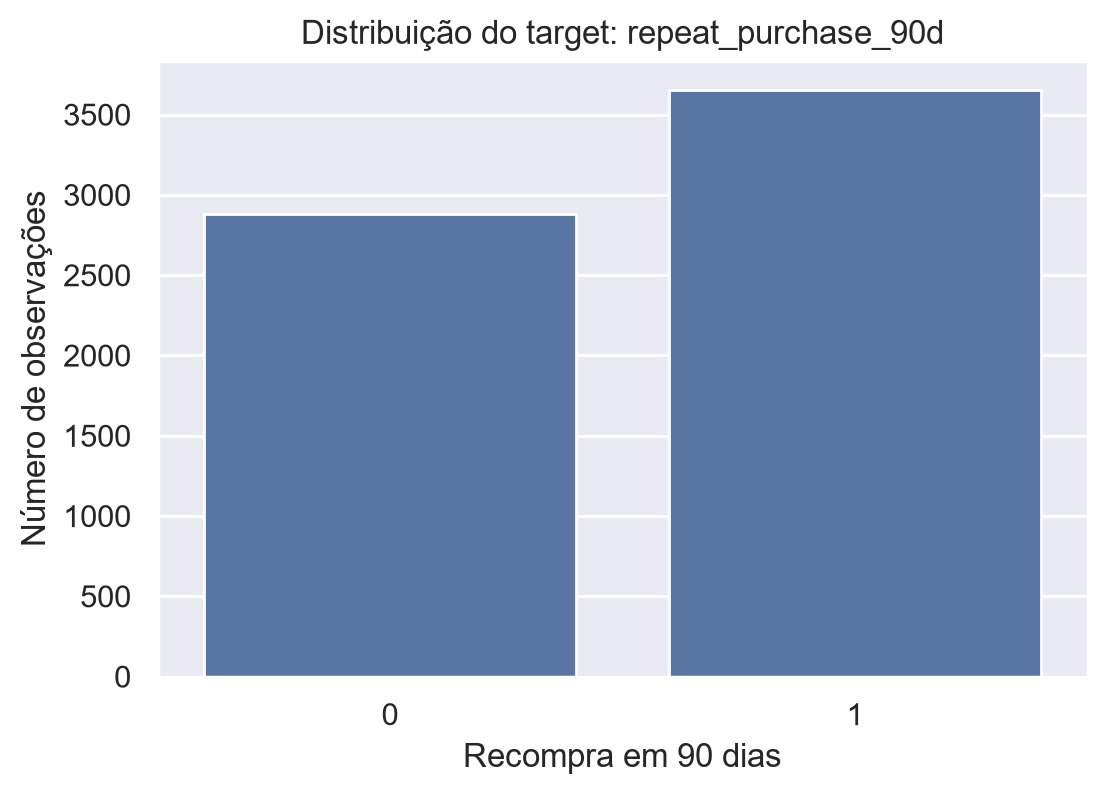

In [2]:
target = "repeat_purchase_90d"

target_summary = pd.DataFrame({
    "count": df[target].value_counts(),
    "proportion": df[target].value_counts(normalize=True).round(3)
})

display(target_summary)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x=target, ax=ax)
ax.set_title("Distribuição do target: repeat_purchase_90d")
ax.set_xlabel("Recompra em 90 dias")
ax.set_ylabel("Número de observações")
plt.show()

O target é binário: 1 significa que o cliente voltou a comprar nos 90 dias seguintes e 0 significa que não voltou.

A distribuição das classes mostra se existe desequilíbrio. Se uma classe for claramente maioritária, a accuracy pode ser enganadora: um modelo que prevê sempre a classe maioritária pode ter boa accuracy sem identificar corretamente os clientes que recompram. Por isso, a avaliação posterior deve dar prioridade ao F1, recall e precision.

## 3.2 Variáveis numéricas

Esta análise permite identificar a escala das variáveis, valores extremos, assimetrias e possíveis anomalias. Estes resultados orientam o tratamento de outliers e a necessidade de transformações no pré-processamento.

In [3]:
numericas_preditoras = [
    col for col in df.select_dtypes(include="number").columns
    if col not in ["ID", "customer_id", target]
]

display(
    df[numericas_preditoras]
    .describe()
    .round(2)
    .T
)

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


**Insight:**  
As variáveis monetárias e históricas apresentam distribuições assimétricas, com máximos muito superiores à mediana. Isto indica a presença de outliers ou clientes com padrões de compra muito distintos.

Estes resultados sugerem que o pré-processamento deverá considerar o tratamento de valores extremos e, se necessário, transformações para reduzir o impacto de escalas muito diferentes.

## 3.3 Relação das variáveis numéricas com o target

Calcula-se a correlação de cada variável numérica com `repeat_purchase_90d`. Variáveis com maior correlação absoluta são candidatas prioritárias a ter valor preditivo.

,correlation_with_target
purchase_count_365d,0.340
purchase_count_180d,0.334
purchase_count_90d,0.328
spend_180d,0.301
prior_purchase_count,0.299
spend_90d,0.269
purchase_count_30d,0.263
prior_total_spend,0.262
prior_mean_gap_days,-0.238
prior_std_gap_days,-0.205


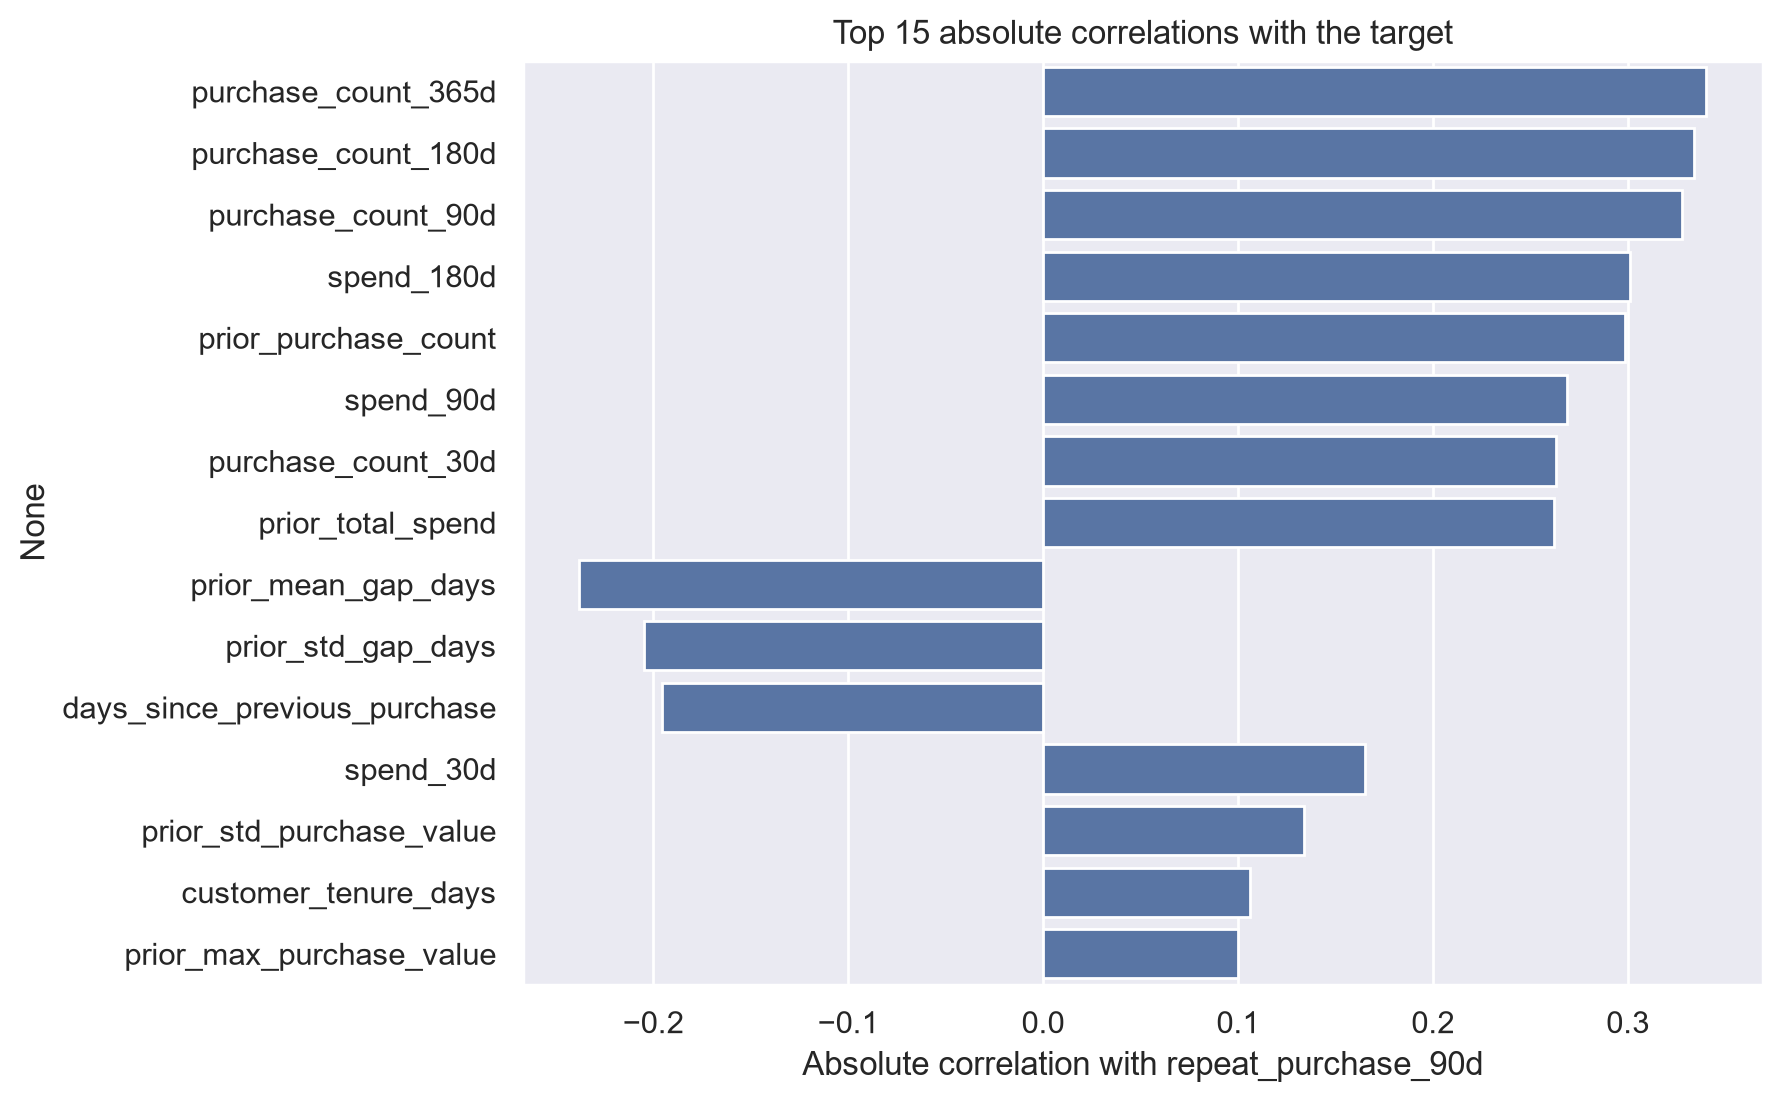

In [4]:
correlacoes_target = (
    df[numericas_preditoras + [target]]
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

display(
    correlacoes_target
    .round(3)
    .to_frame("correlation_with_target")
)

top_corr = correlacoes_target.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=top_corr.values, y=top_corr.index, ax=ax)
ax.set_title("Top 15 absolute correlations with the target")
ax.set_xlabel("Absolute correlation with repeat_purchase_90d")
plt.show()

**Insight:**  
As variáveis com maior correlação absoluta com o target estão associadas ao histórico de compras do cliente, nomeadamente recência, frequência e valor gasto.

A variável `random_noise` apresenta correlação próxima de zero, confirmando que não contém informação útil para prever a recompra. Por isso, será removida antes da modelação.

## 3.4 Redundância entre variáveis numéricas

Para identificar variáveis que transmitem informação muito semelhante, analisa-se a correlação absoluta entre pares de variáveis numéricas. Pares com correlação elevada podem ser redundantes e aumentar desnecessariamente a dimensionalidade do modelo.

In [5]:
corr_matrix = df[numericas_preditoras].corr().abs()

mask = np.triu(np.ones(corr_matrix.shape), k=0).astype(bool)
corr_pares = corr_matrix.mask(mask)

pares_correlacionados = (
    corr_pares
    .stack()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("absolute_correlation")
)

display(pares_correlacionados.round(3))

absolute_correlation
Total Liquido       Total a Pagar                        0.996
                    Total Bruto                          0.984
Total Bruto         Total a Pagar                        0.975
purchase_count_365d purchase_count_180d                  0.954
purchase_count_180d purchase_count_90d                   0.935
Total Imp_          Total a Pagar                        0.901
purchase_count_365d purchase_count_90d                   0.883
prior_std_gap_days  prior_mean_gap_days                  0.872
Total Imp_          Total Liquido                        0.860
spend_180d          spend_90d                            0.856
purchase_count_90d  purchase_count_30d                   0.845
Custo               Total a Pagar                        0.819
Total Imp_          Total Bruto                          0.812
purchase_count_365d prior_purchase_count                 0.804
Custo               Total Liquido                        0.803
                    Total Imp_                           0.803
                    Total Bruto                          0.795
purchase_count_180d purchase_count_30d                   0.782
                    prior_purchase_count                 0.754
purchase_count_365d purchase_count_30d                   0.746

**Insight:**  
Existem pares de variáveis com correlação absoluta elevada, o que indica redundância. Estas variáveis serão consideradas na estratégia de seleção de features, de modo a reduzir dimensionalidade sem perder informação relevante.

## 3.5 Variáveis categóricas e o target

Para cada variável categórica com cardinalidade razoável, compara-se a taxa média de recompra entre categorias. Diferenças relevantes nas taxas de recompra sugerem que a variável pode ter valor preditivo.

Variáveis com cardinalidade muito elevada, como `company_name`, `address`, `postal_code` e `street`, não são tratadas como categorias normais porque se aproximam de identificadores.

In [6]:
categoricas_todas = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

categoricas_para_analisar = [
    col for col in categoricas_todas
    if col != "purchase_date"
    and df[col].nunique(dropna=True) <= 35
]

for coluna in categoricas_para_analisar:
    print("\n" + "=" * 70)
    print("Variável:", coluna)
    print("Valores distintos:", df[coluna].nunique(dropna=True))
    print("Missing:", df[coluna].isna().sum())

    display(
        df[coluna]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("frequency")
    )

    display(
        df
        .groupby(coluna, dropna=False)[target]
        .agg(
            n_observations="count",
            repeat_rate="mean"
        )
        .sort_values("n_observations", ascending=False)
        .head(10)
        .round(3)
    )


Variável: payment_type
Valores distintos: 9
Missing: 260


C:\Users\jcori\AppData\Local\Temp\ipykernel_13468\654602156.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas_todas = df.select_dtypes(


,frequency
payment_type,
Maybe Tomorrow Payment 7,4565
Maybe Tomorrow Payment 12,991
Maybe Tomorrow Payment 9,502
NaN,260
Maybe Tomorrow Payment 10,134
Maybe Tomorrow Payment 8,40
Maybe Tomorrow Payment 2,21
Maybe Tomorrow Payment 4,9
Maybe Tomorrow Payment 11,8


,n_observations,repeat_rate
payment_type,,
Maybe Tomorrow Payment 7,4565,0.527
Maybe Tomorrow Payment 12,991,0.543
Maybe Tomorrow Payment 9,502,0.950
NaN,260,0.550
Maybe Tomorrow Payment 10,134,0.403
Maybe Tomorrow Payment 8,40,0.325
Maybe Tomorrow Payment 2,21,0.524
Maybe Tomorrow Payment 4,9,0.444
Maybe Tomorrow Payment 11,8,0.625



Variável: salesperson
Valores distintos: 9
Missing: 259


...

,frequency
warehouse,
Final Excel Warehouse 1,6253
NaN,260
Final Excel Warehouse 3,21


,n_observations,repeat_rate
warehouse,,
Final Excel Warehouse 1,6253,0.557
NaN,260,0.604
Final Excel Warehouse 3,21,0.810



Variável: document_series
Valores distintos: 3
Missing: 65


,frequency
document_series,
Ctrl Z Series 2,2738
Ctrl Z Series 3,1903
Ctrl Z Series 1,1828
NaN,65


,n_observations,repeat_rate
document_series,,
Ctrl Z Series 2,2738,0.558
Ctrl Z Series 3,1903,0.561
Ctrl Z Series 1,1828,0.561
NaN,65,0.508


**Insight:**  
Algumas variáveis categóricas apresentam diferenças relevantes na taxa de recompra entre categorias, pelo que podem contribuir para o modelo. No entanto, categorias com muito poucas observações devem ser interpretadas com cuidado, porque a taxa estimada pode ser pouco estável.

As variáveis com cardinalidade muito elevada serão removidas ou tratadas separadamente, uma vez que funcionam quase como identificadores e não generalizam bem para novos clientes.

## 3.6 Avaliação de variáveis potencialmente problemáticas

Antes de avançar para o pré-processamento, avaliam-se variáveis que podem exigir decisões específicas:

- `random_noise`: o enunciado indica que a sua utilidade deve ser avaliada, pelo que não será descartada apenas com base no nome;
- `customer_type`: apresenta valores em falta;
- colunas de `clientes.csv` com cardinalidade muito elevada, que podem comportar-se quase como identificadores.

Estatísticas de random_noise:


count    6469.000
mean       -0.022
std         1.001
min        -3.529
25%        -0.678
50%        -0.046
75%         0.642
max         4.151
Name: random_noise, dtype: float64


Correlação com o target:
-0.012


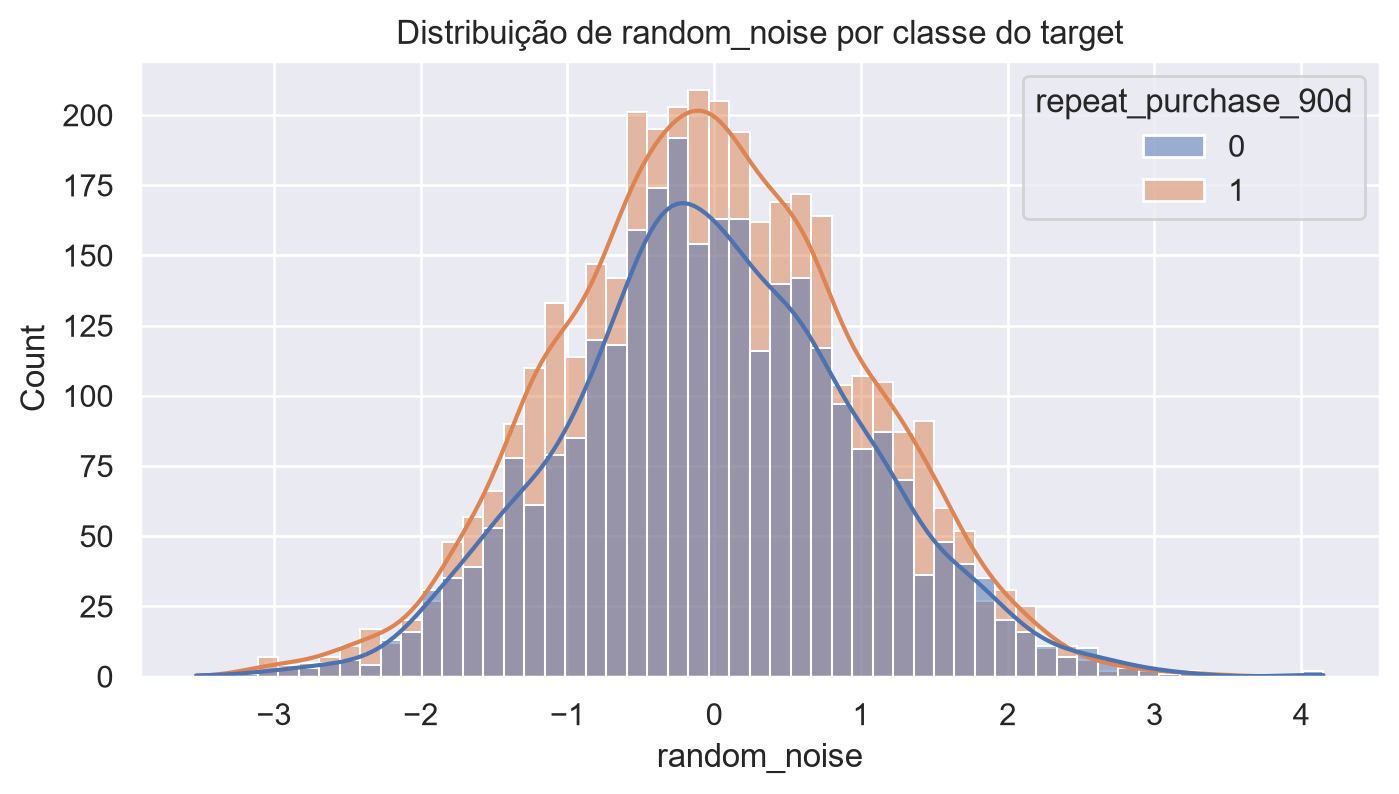

In [7]:
print("Estatísticas de random_noise:")
display(df["random_noise"].describe().round(3))

print("\nCorrelação com o target:")
print(df["random_noise"].corr(df[target]).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=df,
    x="random_noise",
    hue=target,
    kde=True,
    ax=ax
)
ax.set_title("Distribuição de random_noise por classe do target")
plt.show()

**Insight:**  
A variável `random_noise` é avaliada com base na sua distribuição por classe do target e na correlação com `repeat_purchase_90d`. A decisão sobre a sua inclusão no modelo será tomada na etapa de feature selection, comparando o desempenho do modelo com e sem esta variável, em vez de a remover apenas com base no nome.
    

# 4.1 Join with clientes.csv

Nesta secção, o conjunto de treino é enriquecido com informação ao nível do cliente, através de um left join na chave `customer_id`. Posteriormente, as novas colunas são exploradas para decidir quais devem entrar no modelo.

In [8]:
print("Linhas antes do merge:", len(df))
print("Colunas antes do merge:", df.shape[1])

df = df.merge(
    clientes,
    on="customer_id",
    how="left"
)

print("\nLinhas depois do merge:", len(df))
print("Colunas depois do merge:", df.shape[1])
print("Duplicados nas colunas:", df.duplicated().sum())

(df.head())

Linhas antes do merge: 6534
Colunas antes do merge: 38

Linhas depois do merge: 6534
Colunas depois do merge: 50
Duplicados nas colunas: 10


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,NaN,Municipality MU89: Council of Last Minute Edits,City CY286: Cached Result Falls,Postal area PA228: Hidden Sheet Sector,Postal code PC444: #REF! Delivery Route,Street ST303: Absolute Reference Terrace,Address AD761: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1013,2024
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,Island IS8: The Pivot Archipelago,Municipality MU11: Council of Last Minute Edits,City CY147: VLOOKUP Bay,Postal area PA260: Hidden Sheet Sector,Postal code PC636: #REF! Delivery Route,NaN,Address AD382: Cell Without a Home,NaN,Excel Is Not A Database Ltd 35,2015
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,NaN,Municipality MU70: Council of Last Minute Edits,City CY265: Where-less Query Falls,Postal area PA84: Hidden Sheet Sector,Postal code PC200: #REF! Delivery Route,NaN,Address AD723: Cell Without a Home,NaN,Excel Is Not A Database Ltd 826,2017
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,Island IS7: The Pivot Archipelago,Municipality MU12: Council of Last Minute Edits,NaN,Postal area PA253: Hidden Sheet Sector,Postal code PC558: #REF! Delivery Route,Street ST144: Last Save Court,Address AD399: Cell Without a Home,NaN,Excel Is Not A Database Ltd 530,2018
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,NaN,Municipality MU142: Council of Last Minute Edits,City CY359: Spill Error Ridge,Postal area PA136: Hidden Sheet Sector,Postal code PC300: #REF! Delivery Route,Street ST395: AutoFill Path,Address AD928: Cell Without a Home,NaN,Excel Is Not A Database Ltd 220,2017


# 4.2 - EDA AFTER JOIN

## 4.2.1- Visão geral das novas colunas
Após o join, o `df` inclui as colunas de `clientes.csv`. Esta análise identifica o tipo, cardinalidade e valores em falta de cada nova variável, antes de decidir como serão tratadas no pré-processamento.

,dtype,nunique,missing,missing_pct
company_name,str,609,0,0.00
address,str,600,0,0.00
postal_code,str,519,225,3.44
street,str,266,3834,58.68
city,str,260,2150,32.90
postal_area,str,189,278,4.25
municipality,str,150,217,3.32
commercial_region,str,32,35,0.54
customer_since_year,int64,10,0,0.00
island,str,10,2211,33.84


C:\Users\jcori\AppData\Local\Temp\ipykernel_13468\1108866038.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_cli.values, y=missing_cli.index, ax=ax, palette="Blues_r")


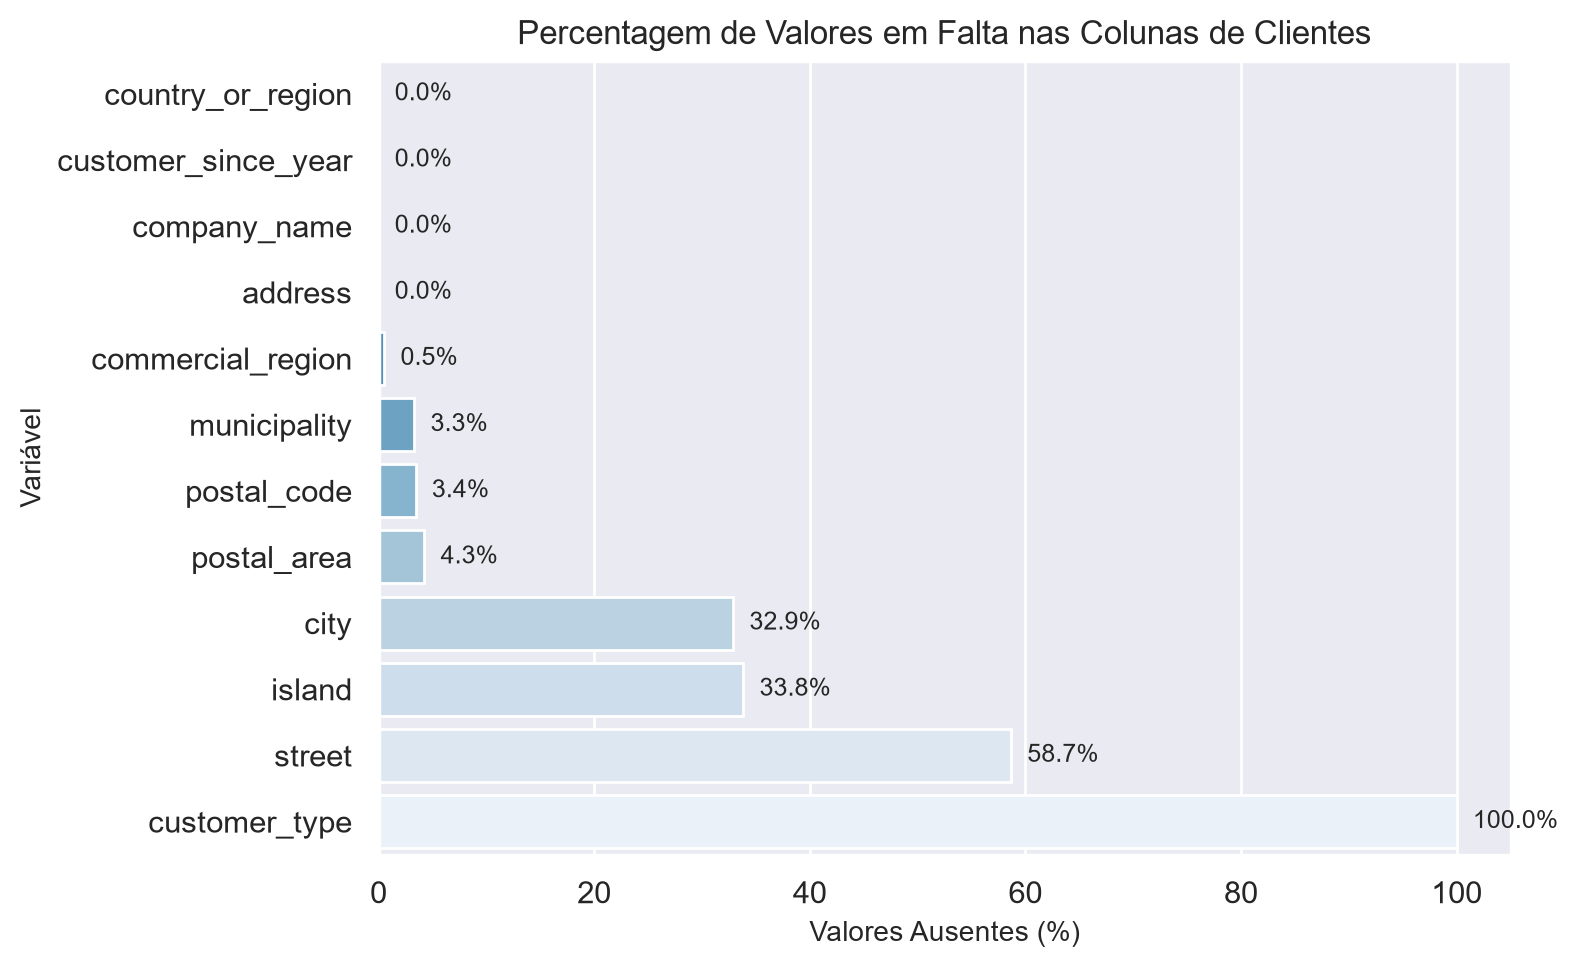

In [17]:
novas_colunas = [
    col for col in clientes.columns
    if col != "customer_id"
]

resumo_novas = pd.DataFrame({
    "dtype": df[novas_colunas].dtypes.astype(str),
    "nunique": df[novas_colunas].nunique(dropna=True),
    "missing": df[novas_colunas].isna().sum(),
    "missing_pct": (df[novas_colunas].isna().mean() * 100).round(2)
}).sort_values("nunique", ascending=False)

display(resumo_novas)

# Gráfico de percentagem de valores em falta em clientes.csv
missing_cli = (df[novas_colunas].isna().mean() * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=missing_cli.values, y=missing_cli.index, ax=ax, palette="Blues_r")
ax.set_title("Percentagem de Valores em Falta nas Colunas de Clientes", fontsize=12)
ax.set_xlabel("Valores Ausentes (%)", fontsize=10)
ax.set_ylabel("Variável", fontsize=10)
ax.set_xlim(0, 105)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.1f}%", (width + 1.5, p.get_y() + p.get_height() / 2),
                ha="left", va="center", fontsize=9)

plt.tight_layout()
plt.show()

**Insight:**  
As colunas com cardinalidade muito elevada, como `company_name`, `address` e `postal_code`, aproximam-se de identificadores e exigem cuidado na codificação. As colunas com baixa cardinalidade, como `country_or_region`, `island` e `commercial_region`, são candidatas naturais a variáveis categóricas do modelo.

### 4.2.2 Variáveis numéricas de clientes e o target

Para as novas colunas numéricas, calcula-se a correlação com `repeat_purchase_90d`, tal como foi feito para as variáveis do `train.csv`. Isto permite perceber se a informação de cliente acrescenta sinal preditivo.

In [11]:
numericas_novas = [
    col for col in novas_colunas
    if df[col].dtype in ["int64", "float64"]
]

correlacoes_novas = (
    df[numericas_novas + [target]]
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)


display(
    correlacoes_novas
    .round(3)
    .to_frame("correlation_with_target")
)

,correlation_with_target
customer_since_year,-0.125
customer_type,NaN


**Insight:**  
As correlações das novas variáveis numéricas com o target indicam se a informação de cliente complementa a informação transacional. Valores próximos de zero não eliminam automaticamente a variável, mas sugerem que o seu valor preditivo, se existir, poderá ser não linear.

### 4.2.3 Variáveis categóricas de clientes e o target

Para as novas colunas categóricas com cardinalidade razoável, compara-se a taxa média de recompra entre categorias. Diferenças relevantes sugerem que a variável pode contribuir para o modelo.

In [12]:
categoricas_clientes = [
    col for col in novas_colunas
    if col not in ["customer_since_year", "customer_type", "company_name", "address", "postal_code", "street"]
]

for col in categoricas_clientes:
    print("\n" + "=" * 60)
    print(f"Variável: {col}")
    print(f"Valores distintos: {df[col].nunique(dropna=True)}")
    print(f"Missing: {df[col].isna().sum()} ({df[col].isna().mean()*100:.2f}%)")
    
    display(
        df.groupby(col, dropna=False)[target]
        .agg(n_observations="count", repeat_rate="mean")
        .sort_values("n_observations", ascending=False)
        .head(10)
        .round(3)
    )


Variável: country_or_region
Valores distintos: 7
Missing: 0 (0.00%)


,n_observations,repeat_rate
country_or_region,,
Country CT10: Land of The Final Version,6321,0.565
Country CT5: Land of The Final Version,194,0.392
Country CT6: Land of The Final Version,8,0.500
Country CT7: Land of The Final Version,8,0.375
Country CT4: Land of The Final Version,1,0.000
Country CT8: Land of The Final Version,1,0.000
Country CT9: Land of The Final Version,1,0.000



Variável: commercial_region
Valores distintos: 32
Missing: 35 (0.54%)


,n_observations,repeat_rate
commercial_region,,
Region RG17: We Will See Later,4109,0.519
Region RG23: We Will See Later,564,0.824
Region RG18: We Will See Later,368,0.620
Region RG24: We Will See Later,235,0.945
Region RG29: We Will See Later,214,0.505
Region RG27: We Will See Later,194,0.649
Region RG31: We Will See Later,165,0.461
Region RG28: We Will See Later,120,0.442
Region RG9: We Will See Later,119,0.445



Variável: island
Valores distintos: 10
Missing: 2211 (33.84%)


...

,n_observations,repeat_rate
municipality,,
Municipality MU1: Council of Last Minute Edits,566,0.549
Municipality MU17: Council of Last Minute Edits,506,0.518
Municipality MU70: Council of Last Minute Edits,455,0.890
Municipality MU9: Council of Last Minute Edits,403,0.596
Municipality MU3: Council of Last Minute Edits,375,0.424
Municipality MU16: Council of Last Minute Edits,296,0.459
Municipality MU15: Council of Last Minute Edits,295,0.681
Municipality MU11: Council of Last Minute Edits,273,0.487
Municipality MU2: Council of Last Minute Edits,268,0.597



Variável: city
Valores distintos: 260
Missing: 2150 (32.90%)


,n_observations,repeat_rate
city,,
NaN,2150,0.551
City CY265: Where-less Query Falls,277,0.993
City CY37: Conditional Format Borough,238,0.622
City CY194: PowerPoint New Hills,219,0.539
City CY281: Null Value Falls,203,1.000
City CY71: Spill Error Harbor,145,0.566
City CY190: Cached Result Grove,134,0.545
City CY147: VLOOKUP Bay,134,0.627
City CY180: Frozen Pane Grove,112,0.946



Variável: postal_area
Valores distintos: 189
Missing: 278 (4.25%)


,n_observations,repeat_rate
postal_area,,
Postal area PA259: Hidden Sheet Sector,565,0.550
Postal area PA252: Hidden Sheet Sector,459,0.508
Postal area PA84: Hidden Sheet Sector,445,0.906
Postal area PA265: Hidden Sheet Sector,375,0.424
Postal area PA261: Hidden Sheet Sector,296,0.459
Postal area PA267: Hidden Sheet Sector,295,0.681
NaN,278,0.414
Postal area PA264: Hidden Sheet Sector,260,0.627
Postal area PA247: Hidden Sheet Sector,256,0.527


**Insight:**  
A variável `country_or_region` apresenta variância quase nula, com mais de 96% dos registos concentrados numa única categoria. 

As colunas `municipality`, `city` e `postal_area` possuem cardinalidade excessiva (entre 150 e 260 categorias distintas) e percentagens elevadas de valores omissos, pelo que não devem ser codificadas diretamente para evitar sobreajustamento (*overfitting*).

Pelo contrário, `commercial_region` e `island` revelam diferenciação relevante na taxa de recompra. Em particular, a categoria `NaN` em `island` apresenta comportamento próprio e volume expressivo (~34%), devendo ser tratada como categoria informativa ("Continente/Não-ilha") em vez de valor em falta descartável.

## 4.3 Qualidade dos dados e anomalias

Nesta secção identificam-se observações sem histórico transacional, registos temporais incongruentes e valores extremos que desvirtuam as escalas das variáveis.

### 4.3.1 Observações sem histórico transacional (linhas nulas)

Avaliação de linhas que contêm apenas identificadores e variável-alvo, sem preenchimento nas variáveis descritivas da transação.

In [13]:
colunas_transacionais = [
    c for c in df.columns 
    if c not in ["ID", "customer_id", target] and df[c].isna().sum() == 65
]

linhas_vazias_65 = df[df[colunas_transacionais].isna().all(axis=1)]

print(f"Observações com preditores transacionais totalmente a nulo: {len(linhas_vazias_65)}")
display(linhas_vazias_65[["customer_id", target]].head())

Observações com preditores transacionais totalmente a nulo: 65


,customer_id,repeat_purchase_90d
393,755628,1
484,755628,1
582,427118,1
583,508217,0
748,427118,0


**Insight:**  
Existem 65 observações (0.99% do total) desprovidas de qualquer informação transacional ou comportamental, conservando unicamente o `customer_id` e a classe `repeat_purchase_90d`. A imputação de 24 variáveis em simultâneo criaria dados sintéticos sem fundamentação, justificando-se a sua remoção na etapa de pré-processamento.

### 4.3.2 Inconsistências temporais e valores extremos de sistema

Identificação de intervalos temporais negativos e deteção de ordens de grandeza anómalas nas variáveis monetárias.

Outliers na ordem de 10^9:


,customer_id,prior_mean_purchase_value,spend_365d,prior_total_spend
196,112532,1.000000e+09,NaN,12364.88
267,175924,1.000000e+09,3.094490e+03,8663.31
916,239651,1.323003e+02,1.000000e+09,8467.22
1029,258332,9.027120e+02,1.000000e+09,102909.17
1618,856505,1.000000e+09,6.293690e+03,10323.88
1630,924977,NaN,1.000000e+09,0.00
1941,688367,1.005663e+03,1.000000e+09,51288.79
2356,309223,8.705900e+02,1.000000e+09,1741.18
2369,475951,2.114369e+03,1.000000e+09,118404.68
2386,218902,1.000000e+09,5.074040e+03,5074.04



Ocorrências com dias negativos em 'days_since_previous_purchase': 16
Ocorrências com dias negativos em 'prior_mean_gap_days': 16


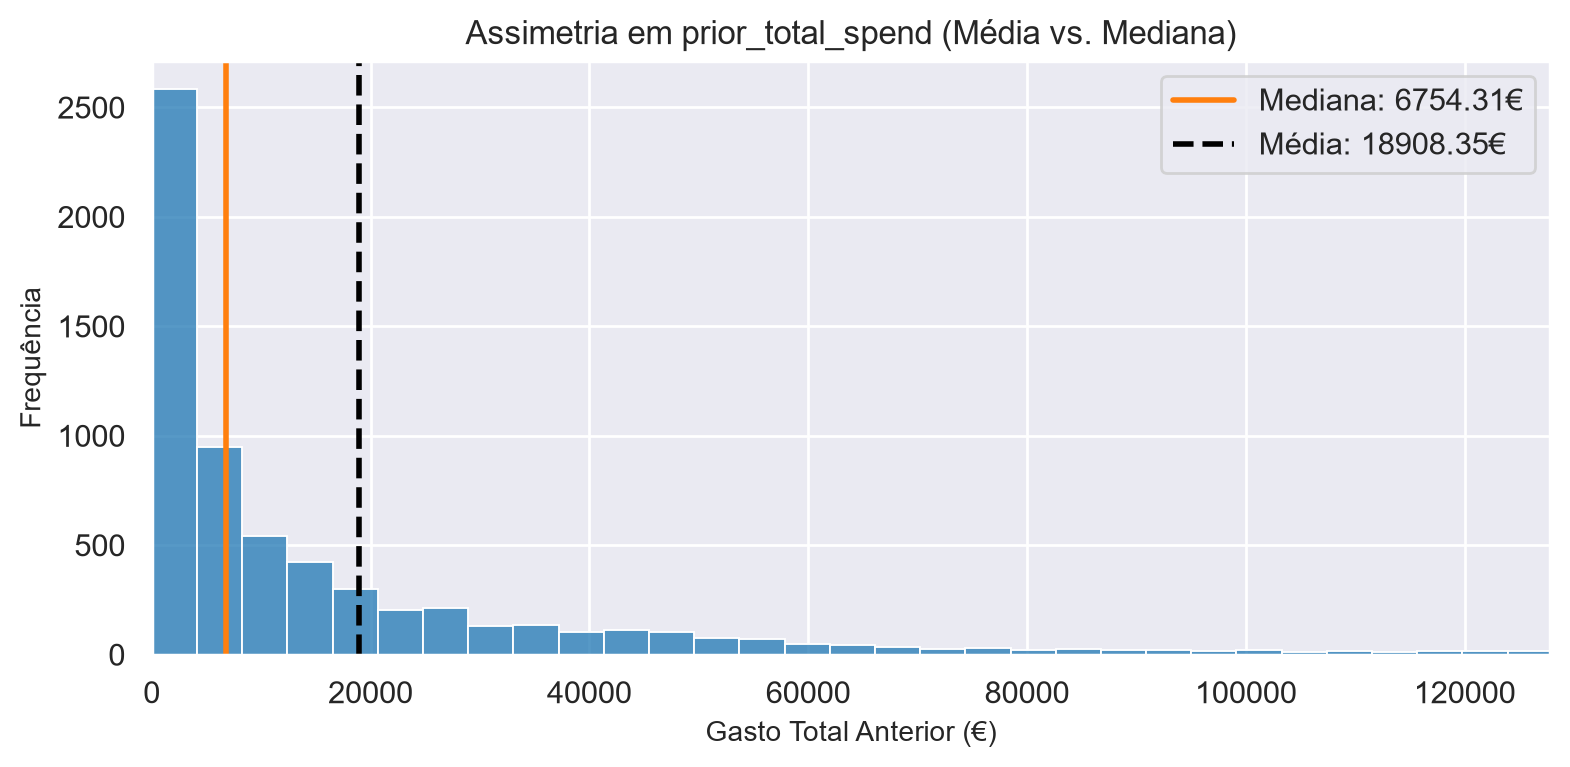

In [19]:
# 1. Outliers de sistema na escala de 10^9
outliers_bilhao = df[
    (df["prior_mean_purchase_value"] >= 1e8) | (df["spend_365d"] >= 1e8)
][["customer_id", "prior_mean_purchase_value", "spend_365d", "prior_total_spend"]]

# 2. Inconsistências lógicas em variáveis de contagem de dias
dias_negativos = (df["days_since_previous_purchase"] < 0).sum()
gap_negativos = (df["prior_mean_gap_days"] < 0).sum()

print("Outliers na ordem de 10^9:")
display(outliers_bilhao)

print(f"\nOcorrências com dias negativos em 'days_since_previous_purchase': {dias_negativos}")
print(f"Ocorrências com dias negativos em 'prior_mean_gap_days': {gap_negativos}")

# Distribuição de gastos anteriores com mediana vs média
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["prior_total_spend"].dropna(), bins=60, color="#1f77b4", ax=ax)
med = df["prior_total_spend"].median()
avg = df["prior_total_spend"].mean()

ax.axvline(med, color="#ff7f0e", lw=2, label=f"Mediana: {med:.2f}€")
ax.axvline(avg, color="black", lw=2, ls="--", label=f"Média: {avg:.2f}€")
ax.set_title("Assimetria em prior_total_spend (Média vs. Mediana)", fontsize=12)
ax.set_xlabel("Gasto Total Anterior (€)", fontsize=10)
ax.set_ylabel("Frequência", fontsize=10)
ax.set_xlim(0, df["prior_total_spend"].quantile(0.98))
ax.legend()

plt.tight_layout()
plt.show()

**Insight:**  
Os montantes de 1.000.000.000,00 detetados em `prior_mean_purchase_value` e `spend_365d` representam valores sentinela de erro de sistema que distorcem severamente as médias amostrais. 

Os valores de `-4.0` dias em métricas temporais configuram anomalias de cálculo ou registo retrodatado, devendo ser truncados a zero ou tratados como ausentes. Valores negativos em `spend_365d` correspondem a notas de crédito e devoluções que superaram o volume comprado no período homólogo.

## 4.4 Síntese da EDA e diretrizes para o pré-processamento

Com base nas conclusões da exploração de dados, definem-se as seguintes regras de preparação para a fase de modelação:

1. **Limpeza de registos:** Eliminação das 65 observações sem preditores transacionais e correção/imputação dos valores aberrantes de $10^9$ e temporais negativos (-4 dias).
2. **Seleção e eliminação de variáveis:** Remoção de `random_noise` por ausência de poder discriminativo, e de `customer_type` por conter 100% de valores omissos. Exclusão de identificadores puros (`ID`, `customer_id`, `company_name`, `address`).
3. **Agregação e codificação categórica:** Descarte de variáveis de localização com elevada dispersão (`municipality`, `city`, `postal_area`) e agrupamento das categorias raras em `commercial_region`. Tratamento de valores omissos em `island` como categoria informativa "Continente".
4. **Tratamento de multicolinearidade:** Redução da redundância verificada entre variáveis acumuladas de faturação (`Total a Pagar`, `Total Bruto`, `Total Liquido`) e métricas em janelas temporais sobrepostas (30d, 90d, 180d, 365d).